# Studiul de caz 4 - O baterie pe piața pentru ziua următoare: rețele neuronale cuantilice și reinforcement learning

Master - Rețele neuronale și deep learning (NN) - Prof. Daniel Traian Pele

Academia de Studii Economice din București - Academia Română, Institutul de Prognoză Economică

In [1]:
# Google Colab: copiem repo-ul cursului, ca datele și rezultatele salvate să fie găsite
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/NEURAL_BIZ'):
    if not os.path.isdir('/content/NEURAL_BIZ'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/NEURAL_BIZ.git', '/content/NEURAL_BIZ'], check=True)
    os.chdir('/content/NEURAL_BIZ/cases/C4_battery_arbitrage')

In [2]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.join("..", "common"))   # shared helpers: cases/common/case_utils.py
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import case_utils as cu
LANG = "ro"            # "en" or "ro": language of the charts shown below (both are saved)
cu.set_lang(LANG)
T = lambda en, ro: cu.T(LANG, en, ro)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
%matplotlib inline

**Lucrarea de referință.** Andrei, A.-V., Cepoi, C. O., Dumitrescu, B. A., Lessmann, S., Chiriac (Luchian), A.-C., Pele, D. T. și Petukhina, A. (2026).
Joint probabilistic forecasting for battery arbitrage in day-ahead power markets. SSRN, document de lucru 6872381. doi:10.2139/ssrn.6872381

**Conținutul notebook-ului.** O baterie de 1 MW / 1 MWh, cu randament de 90 %, efectuează cel mult un ciclu de încărcare-descărcare pe zi pe piața pentru ziua următoare din România.
Ca în lucrare, bateria este operată *ex ante*: orele se aleg pe baza unei prognoze probabilistice a celor 24 de prețuri din ziua următoare, iar rezultatul se compară cu
o pereche fixă de ore (reperul naiv) și cu previziunea perfectă (limita superioară); investiția este apoi evaluată prin valoarea actualizată netă (VAN) și perioada de recuperare.
Versiunea cu rețele neuronale: (1) un **perceptron multistrat (MLP, *multilayer perceptron*) cuantilic**, antrenat cu funcția de pierdere *pinball*, estimează nouă cuantile pentru fiecare dintre cele 24 de prețuri;
(2) un **agent Q-learning tabelar** (cursul 10) învață cînd să încarce și cînd să descarce bateria pe baza ordinii orelor din prognoză.

**Adaptarea pentru curs.** Lucrarea folosește modele DRF (*Distributional Random Forests*) cu 37 de variabile fundamentale pentru România, Bulgaria, Ungaria și Cehia
(ianuarie 2018 - septembrie 2024). Noi folosim numai prețurile anterioare din România, Bulgaria și Ungaria și variabile calendaristice; rețelele sînt antrenate pe
2019-2022 (pentru agent) și pe 2019-2024 (prognoza finală); perioada de test este ianuarie 2025 - octombrie 2026, după eșantionul lucrării.
Fiecare rețea și fiecare agent sînt estimați cu cinci valori inițiale (*seeds*) diferite.

## 1. Datele: profilul zilnic al prețului și bateria

RO days with 24 prices: 3207 of 3226
annuity factor 9.108 -> profit needed per year 54897 EUR


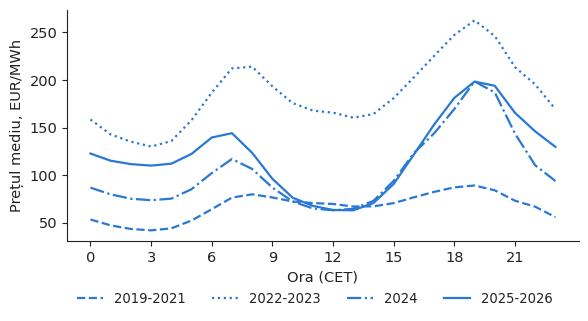

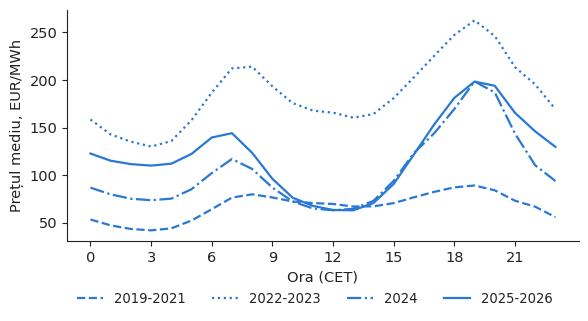

In [3]:
import torch                                   # imported before scikit-learn (course rule)
torch.set_num_threads(4)
ph = cu.prices_hourly("Europe/Brussels")[["RO", "BG", "HU"]].loc[:"2026-10-31 23:59"]   # CET/CEST delivery hours
ph["day"] = ph.index.tz_localize(None).normalize(); ph["hour"] = ph.index.hour
def day_matrix(z):
    """Delivery days x 24 hours; only days with 24 reported hours (the clock-change days are dropped)."""
    x = ph[["day", "hour", z]].dropna()
    cnt = x.groupby("day")[z].count()
    return x[x.day.isin(cnt[cnt == 24].index)].pivot_table(index="day", columns="hour", values=z).sort_index()
D = {z: day_matrix(z) for z in ["RO", "BG", "HU"]}
cal = pd.date_range("2018-01-01", "2026-10-31", freq="D")
D = {z: m.reindex(cal) for z, m in D.items()}          # calendar grid: a lag of one row = one calendar day; missing days stay missing
P = D["RO"].values
print("RO days with 24 prices:", int(np.isfinite(P).all(1).sum()), "of", len(cal))
ETA = 0.9                                              # efficiency applied on both legs, as in the paper: profit = eta*p_sell - p_buy/eta
CAPEX, LIFE, RATE = 500_000, 15, 0.07                  # paper's baseline assumptions (EUR, years, discount rate)
ANN = sum(1 / (1 + RATE) ** t for t in range(1, LIFE + 1))
NEED = CAPEX / ANN                                     # annual profit that makes NPV = 0
print("annuity factor %.3f -> profit needed per year %.0f EUR" % (ANN, NEED))
def fig_shape(lang):
    fig, ax = plt.subplots(figsize=(6.6, 3.0))
    for (a, b), ls in [(("2019", "2021"), "--"), (("2022", "2023"), ":"), (("2024", "2024"), "-."), (("2025", "2026"), "-")]:
        m = D["RO"].loc[a:b].mean()
        lab = a if a == b else f"{a}-{b}"
        ax.plot(m.index, m.values, color=cu.PAL["RO"], ls=ls, lw=1.6, label=lab)
    ax.set_xlabel(cu.T(lang, "Hour (CET)", "Ora (CET)")); ax.set_ylabel(cu.T(lang, "Mean price, EUR/MWh", "Prețul mediu, EUR/MWh")); ax.set_xticks(range(0, 24, 3))
    cu.legend_bottom(fig, ncol=4)
    return fig
cu.save_both(fig_shape, "f1_daily_shape")

## 2. O rețea cuantilică pentru cele 24 de prețuri din ziua următoare

In [4]:
import torch.nn as nn
TAU = np.round(np.arange(0.1, 0.91, 0.1), 2)            # nine quantile levels
def features():
    """Information known before the day-ahead auction for day d (gate closure 12:00 CET on d-1): the 24 prices of d-1 (cleared on d-2) and of d-7,
    the mean prices of d-1 in Bulgaria and Hungary, day of the week (one-hot) and the season (sine and cosine of the day of the year)."""
    R = D["RO"]
    X = pd.concat([R.shift(1).add_prefix("ro1_"), R.shift(7).add_prefix("ro7_"),
                   D["BG"].mean(1).shift(1).rename("bg1"), D["HU"].mean(1).shift(1).rename("hu1"),
                   pd.get_dummies(pd.Series(cal.dayofweek, index=cal), prefix="dow").astype(float),
                   pd.DataFrame({"s": np.sin(2 * np.pi * cal.dayofyear / 365.25), "c": np.cos(2 * np.pi * cal.dayofyear / 365.25)}, index=cal)], axis=1)
    return X
X = features()
ok = X.notna().all(1).values & np.isfinite(P).all(1)
days = cal
def idx(a, b):
    return np.where(ok & (days >= a) & (days <= b))[0]
TR1, VA1 = idx("2019-01-01", "2022-08-31"), idx("2022-09-01", "2022-12-31")      # stage 1: forecasts for 2023-2024 (agent training)
OUT1 = idx("2023-01-01", "2024-12-31")
TR2, VA2 = idx("2019-01-01", "2024-08-31"), idx("2024-09-01", "2024-12-31")      # stage 2: forecasts for the test period
TEST = idx("2025-01-01", "2026-10-31")
print("stage 1: train %d, validation %d, forecast %d days | stage 2: train %d, validation %d, test %d days" % (len(TR1), len(VA1), len(OUT1), len(TR2), len(VA2), len(TEST)))

class QMLP(nn.Module):
    def __init__(self, k):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(k, 128), nn.ReLU(), nn.Dropout(0.1), nn.Linear(128, 128), nn.ReLU(), nn.Dropout(0.1), nn.Linear(128, 24 * len(TAU)))
    def forward(self, x):
        return self.net(x).view(-1, 24, len(TAU))
TAU_T = torch.tensor(TAU, dtype=torch.float32)
def pinball(q, y):                                      # q: n x 24 x 9, y: n x 24
    u = y.unsqueeze(-1) - q
    return torch.maximum(TAU_T * u, (TAU_T - 1) * u).mean()

def fit_qmlp(tr, va, seed, max_epochs=400, patience=30):
    """Scalers fitted on the training days only; early stopping on the (later) validation days."""
    torch.manual_seed(seed); np.random.seed(seed)
    xm, xs = X.values[tr].mean(0), X.values[tr].std(0) + 1e-6
    ym, ys = P[tr].mean(), P[tr].std()
    f = lambda i: torch.tensor((X.values[i] - xm) / xs, dtype=torch.float32)
    g = lambda i: torch.tensor((P[i] - ym) / ys, dtype=torch.float32)
    m = QMLP(X.shape[1]); opt = torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=1e-4)
    xt, yt, xv, yv = f(tr), g(tr), f(va), g(va)
    best, state, wait = np.inf, None, 0
    for ep in range(max_epochs):
        m.train(); perm = torch.randperm(len(tr))
        for b in range(0, len(tr), 64):
            j = perm[b:b + 64]; opt.zero_grad(); loss = pinball(m(xt[j]), yt[j]); loss.backward(); opt.step()
        m.eval()
        with torch.no_grad():
            lv = pinball(m(xv), yv).item()
        if lv < best - 1e-5:
            best, state, wait = lv, {k: v.clone() for k, v in m.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience:
                break
    m.load_state_dict(state); m.eval()
    def predict(i):
        with torch.no_grad():
            q = m(f(i)).numpy() * ys + ym
        return np.sort(q, axis=-1)                        # rearrangement: quantiles do not cross
    return predict, ep + 1

SEEDS = [0, 1, 2, 3, 4]
Q1, Q2, EPOCHS = {}, {}, []
for s in SEEDS:
    pr1, e1 = fit_qmlp(TR1, VA1, s); Q1[s] = pr1(OUT1)
    pr2, e2 = fit_qmlp(TR2, VA2, s); Q2[s] = pr2(TEST); EPOCHS += [e1, e2]
print("epochs until early stop:", EPOCHS)

stage 1: train 1318, validation 119, forecast 719 days | stage 2: train 2037, validation 119, test 658 days


epochs until early stop: [86, 98, 83, 132, 87, 125, 73, 109, 95, 84]


     MAE   CRPS  cover80
0  23.75  18.92    73.88
1  24.05  19.26    74.06
2  24.49  19.55    75.63
3  23.66  18.97    73.93
4  23.67  18.85    77.45
mean over seeds: {'MAE': 23.92, 'CRPS': 19.11, 'cover80': 74.99} | naive 'same hour yesterday' MAE 27.43
paper (DRF, Romania, 2019-2024): MAE 39.63, RMSE 49.60, CRPS 28.12 EUR/MWh


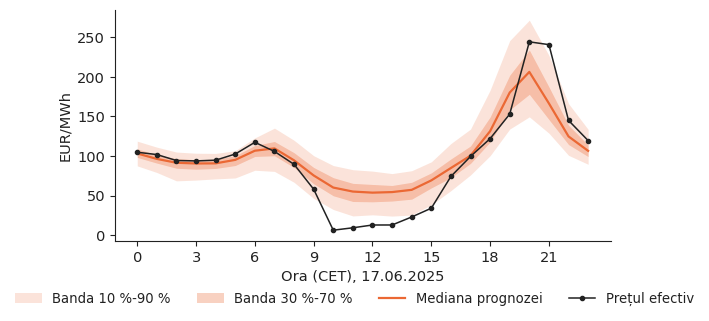

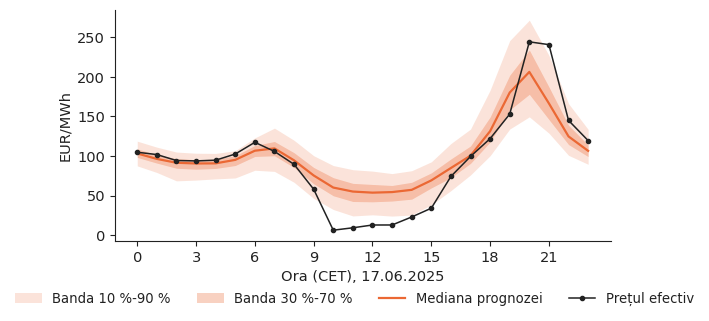

In [5]:
def crps_q(q, y):                                       # CRPS approximated by 2 x the mean pinball loss over the nine quantile levels
    u = y[..., None] - q
    return 2 * np.maximum(TAU * u, (TAU - 1) * u).mean(-1)
Y = P[TEST]
acc = pd.DataFrame({s: {"MAE": np.abs(Y - Q2[s][..., 4]).mean(), "CRPS": crps_q(Q2[s], Y).mean(),
                        "cover80": 100 * ((Y >= Q2[s][..., 0]) & (Y <= Q2[s][..., 8])).mean()} for s in SEEDS}).T
naive_mae = np.abs(Y - P[TEST - 1]).mean()
print(acc.round(2)); print("mean over seeds:", acc.mean().round(2).to_dict(), "| naive 'same hour yesterday' MAE %.2f" % naive_mae)
print("paper (DRF, Romania, 2019-2024): MAE 39.63, RMSE 49.60, CRPS 28.12 EUR/MWh")
QM = np.mean([Q2[s] for s in SEEDS], axis=0)              # average of the five networks, used for the chart
i_ex = int(np.where(days[TEST] == pd.Timestamp("2025-06-17"))[0][0])
def fig_fan(lang):
    fig, ax = plt.subplots(figsize=(6.4, 3.0)); hrs = np.arange(24)
    ax.fill_between(hrs, QM[i_ex, :, 0], QM[i_ex, :, 8], color=cu.PAL["DE_LU"], alpha=0.18, lw=0, label=cu.T(lang, "10 %-90 % band", "Banda 10 %-90 %"))
    ax.fill_between(hrs, QM[i_ex, :, 2], QM[i_ex, :, 6], color=cu.PAL["DE_LU"], alpha=0.30, lw=0, label=cu.T(lang, "30 %-70 % band", "Banda 30 %-70 %"))
    ax.plot(hrs, QM[i_ex, :, 4], color=cu.PAL["DE_LU"], lw=1.6, label=cu.T(lang, "Forecast median", "Mediana prognozei"))
    ax.plot(hrs, Y[i_ex], color=cu.INK, lw=1.1, marker="o", ms=3, label=cu.T(lang, "Actual price", "Prețul efectiv"))
    ax.set_xlabel(cu.T(lang, "Hour (CET), ", "Ora (CET), ") + (f"{days[TEST][i_ex]:%d.%m.%Y}" if lang == "ro" else f"{days[TEST][i_ex]:%Y-%m-%d}"))
    ax.set_ylabel("EUR/MWh"); ax.set_xticks(range(0, 24, 3))
    cu.legend_bottom(fig, ncol=4)
    return fig
cu.save_both(fig_fan, "f2_forecast_fan")

## 3. Regulile de tranzacționare din lucrare aplicate prognozelor noastre

In [6]:
pairs = [(a, b) for a in range(24) for b in range(a + 1, 24)]
A_, B_ = np.array(pairs).T
def spread(M):                                          # profit of every pair (h1 < h2) for each day: eta*p_h2 - p_h1/eta
    return ETA * M[:, B_] - M[:, A_] / ETA
def perfect(Pd):                                        # perfect foresight: best pair each day, ex post (upper bound)
    return np.maximum(spread(Pd).max(1), 0)
def fixed(Pd, Psel):                                    # one pair chosen EX ANTE on an earlier period, traded every day
    k = int(spread(Psel).sum(0).argmax())
    return spread(Pd)[:, k], pairs[k]
def market_orders(Pd, M):                               # pair with the best forecast spread, market orders (always cleared), skip if spread <= 0
    S = spread(M); k = S.argmax(1); go = S[np.arange(len(M)), k] > 0
    return np.where(go, spread(Pd)[np.arange(len(Pd)), k], 0.0)
def quantile_bids(Pd, Qd, alpha=0.8):
    """Paper's quantile-based rule, simplified: pair from the forecast medians; limit bids: buy at the (1-q) quantile of h1, sell at the q quantile
    of h2, q = (1-alpha)/2. If the buy clears and the sell does not, the battery stays full and sells next day at the highest-median hour."""
    q = (1 - alpha) / 2; lv = lambda Qh, t: np.interp(t, TAU, Qh)
    full, out, both = False, [], []
    for p, Qq in zip(Pd, Qd):
        med = Qq[:, 4]
        if full:
            out.append(ETA * p[int(med.argmax())]); full = False; both.append(False); continue
        S = ETA * med[B_] - med[A_] / ETA; k = int(S.argmax())
        if S[k] <= 0:
            out.append(0.0); both.append(False); continue
        a, b = pairs[k]; bought = p[a] <= lv(Qq[a], 1 - q); sold = bought and p[b] >= lv(Qq[b], q)
        pi = -p[a] / ETA if bought else 0.0
        if sold:
            pi += ETA * p[b]
        elif bought:
            full = True
        out.append(pi); both.append(bool(sold))
    return np.array(out), 100 * np.mean(both)

# check against the paper on its own window (8 Jan 2019 - 30 Sep 2024): perfect foresight and fixed hours need no forecast
W = idx("2019-01-08", "2024-09-30"); SELW = np.where(np.isfinite(P).all(1) & (days >= "2018-01-08") & (days < "2019-01-08"))[0]
pfW = perfect(P[W]).sum(); nhW, pairW = fixed(P[W], P[SELW])
print("paper window, %d days: perfect foresight %.0f EUR (paper 188,249), fixed hours %02d->%02d %.0f EUR (paper 133,230)" % (len(W), pfW, *pairW, nhW.sum()))

SEL24 = idx("2024-01-01", "2024-12-31")
res = {"pf": perfect(Y)}
res["nh"], pair24 = fixed(Y, P[SEL24])
res["naive"] = market_orders(Y, P[TEST - 1])                     # yesterday's prices used as the forecast
mlp_mkt = {s: market_orders(Y, Q2[s][..., 4]) for s in SEEDS}
mlp_qb = {s: quantile_bids(Y, Q2[s]) for s in SEEDS}
print("fixed pair chosen on 2024: %02d:00 -> %02d:00" % pair24)
for k, v in res.items():
    print(f"{k:6s} test profit {v.sum():9.0f} EUR")
print("MLP, market orders: %s" % [round(v.sum()) for v in mlp_mkt.values()])
print("MLP, quantile bids alpha=0.8: %s, both bids cleared %%: %s" % ([round(v[0].sum()) for v in mlp_qb.values()], [round(v[1], 1) for v in mlp_qb.values()]))

paper window, 2060 days: perfect foresight 187456 EUR (paper 188,249), fixed hours 03->19 128711 EUR (paper 133,230)
fixed pair chosen on 2024: 12:00 -> 19:00
pf     test profit     95053 EUR
nh     test profit     71205 EUR
naive  test profit     78176 EUR
MLP, market orders: [83501, 81286, 82478, 83940, 83185]
MLP, quantile bids alpha=0.8: [75345, 73121, 74397, 76694, 76289], both bids cleared %: [np.float64(72.2), np.float64(70.5), np.float64(67.9), np.float64(71.0), np.float64(73.4)]


## 4. Un agent de tranzacționare cu reinforcement learning (cursul 10)

In [7]:
NB = 8                                                   # signal: octile of each hour in the day's forecast ranking (0 = three cheapest hours)
def bins(M):
    return M.argsort(1).argsort(1) * NB // 24
def later(B):
    # highest and lowest signal among the hours still to come today (what a trader sees on the forecast curve)
    L = np.zeros(B.shape + (2,), dtype=int)
    for h in range(23):
        L[:, h, 0], L[:, h, 1] = B[:, h + 1:].max(1), B[:, h + 1:].min(1)
    return L
def run_day(Qt, Nv, p, b, l, eps, rng, learn):
    # One delivery day = one episode. State s_h = (state of charge, signal of hour h, highest later signal, lowest later signal).
    # Actions: 0 wait, 1 charge (only if empty), 2 discharge (only if full). One cycle per day: the episode ends after the discharge;
    # a battery still full at 23:00 is discharged then. Reward = cash flow of the hour (EUR), divided by 100 for learning.
    soc, tot = 0, 0.0
    for h in range(24):
        feas = [0, 1] if soc == 0 else [0, 2]
        if h == 23:
            feas = [2] if soc == 1 else [0]
        st = (soc, b[h], l[h, 0], l[h, 1])
        if learn and rng.random() < eps:
            a = feas[rng.integers(len(feas))]
        else:
            a = feas[int(np.argmax(Qt[st][feas]))]
        r = -p[h] / ETA if a == 1 else (ETA * p[h] if a == 2 else 0.0)
        tot += r
        done = a == 2 or h == 23
        soc2 = 1 if a == 1 else (0 if a == 2 else soc)
        if learn:
            nxt = 0.0
            if not done:
                f2 = ([0] if soc2 == 0 else [2]) if h + 1 == 23 else ([0, 1] if soc2 == 0 else [0, 2])
                nxt = Qt[(soc2, b[h + 1], l[h + 1, 0], l[h + 1, 1])][f2].max()
            Nv[st][a] += 1
            Qt[st][a] += Nv[st][a] ** -0.6 * (r / 100 + nxt - Qt[st][a])   # Q-learning, gamma = 1 within the day, step 1/n^0.6
        if done:
            break
        soc = soc2
    return tot
def train_agent(Ptr, Btr, seed, epochs=100):
    rng = np.random.default_rng(seed); Qt = np.zeros((2, NB, NB, NB, 3)); Nv = np.zeros_like(Qt); Ltr = later(Btr); curve = []
    for ep in range(epochs):
        eps = max(0.05, 1 - ep / (0.6 * epochs))            # epsilon-greedy exploration, from 1 down to 0.05
        for d in rng.permutation(len(Ptr)):
            run_day(Qt, Nv, Ptr[d], Btr[d], Ltr[d], eps, rng, True)
        curve.append(np.mean([run_day(Qt, None, Ptr[d], Btr[d], Ltr[d], 0, None, False) for d in range(len(Ptr))]))
    return Qt, curve
def test_agent(Qt, Pd, Bd):
    Ld = later(Bd)
    return np.array([run_day(Qt, None, Pd[d], Bd[d], Ld[d], 0, None, False) for d in range(len(Pd))])
import time; t0 = time.time()
AG = {}
for sig in ["naive", "mlp"]:
    for s in SEEDS:
        Btr = bins(P[OUT1 - 1]) if sig == "naive" else bins(Q1[s][..., 4])      # training days 2023-2024: out-of-sample signals only
        Bte = bins(P[TEST - 1]) if sig == "naive" else bins(Q2[s][..., 4])
        Qt, curve = train_agent(P[OUT1], Btr, s)
        AG[(sig, s)] = dict(Q=Qt, curve=curve, test=test_agent(Qt, Y, Bte), Bte=Bte)
T_RL = time.time() - t0
print("10 agents trained in %.0f s" % T_RL)
for sig in ["naive", "mlp"]:
    print(sig, "test profit by seed:", [round(AG[(sig, s)]["test"].sum()) for s in SEEDS])

10 agents trained in 100 s
naive test profit by seed: [68718, 68799, 68649, 68976, 68631]
mlp test profit by seed: [72242, 69955, 67866, 71375, 71000]


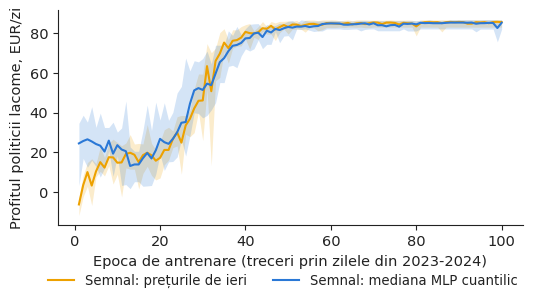

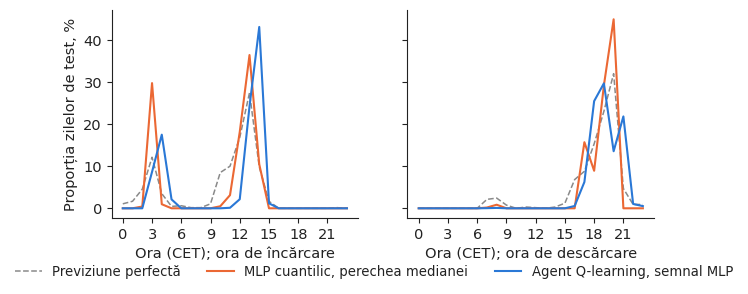

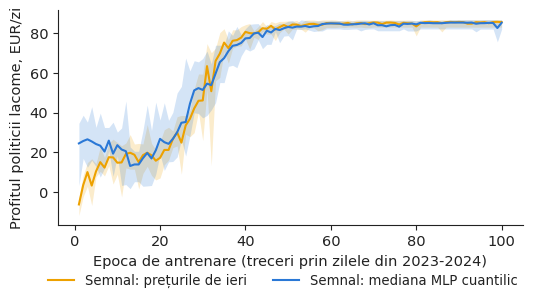

In [8]:
def hours_used(Qt, Bd):
    # hour of the charge and of the discharge chosen by the greedy agent on each test day
    Ld = later(Bd); out = []
    for d in range(len(Bd)):
        soc, hc, hd = 0, None, None
        for h in range(24):
            feas = [0, 1] if soc == 0 else [0, 2]
            if h == 23:
                feas = [2] if soc == 1 else [0]
            a = feas[int(np.argmax(Qt[(soc, Bd[d][h], Ld[d][h, 0], Ld[d][h, 1])][feas]))]
            if a == 1:
                hc, soc = h, 1
            elif a == 2:
                hd = h; break
        out.append((hc, hd))
    return out
use_rl = sum((hours_used(AG[("mlp", s)]["Q"], AG[("mlp", s)]["Bte"]) for s in SEEDS), [])
def rule_hours(M):
    S = spread(M); k = S.argmax(1)
    return [pairs[j] if S[i, j] > 0 else (None, None) for i, j in enumerate(k)]
use_mlp = sum((rule_hours(Q2[s][..., 4]) for s in SEEDS), [])
use_pf = rule_hours(Y)
def share(u, j):
    v = pd.Series([x[j] for x in u if x[j] is not None]).value_counts().reindex(range(24), fill_value=0)
    return 100 * v / len(u)
def fig_hours(lang):
    fig, axs = plt.subplots(1, 2, figsize=(7.0, 2.7), sharey=True)
    for ax, j, ttl in [(axs[0], 0, cu.T(lang, "Charging hour", "Ora de încărcare")), (axs[1], 1, cu.T(lang, "Discharging hour", "Ora de descărcare"))]:
        ax.plot(range(24), share(use_pf, j), color=cu.MUTED, ls="--", lw=1.1, label=cu.T(lang, "Perfect foresight", "Previziune perfectă"))
        ax.plot(range(24), share(use_mlp, j), color=cu.PAL["DE_LU"], lw=1.5, label=cu.T(lang, "Quantile MLP, median pair", "MLP cuantilic, perechea medianei"))
        ax.plot(range(24), share(use_rl, j), color=cu.PAL["RO"], lw=1.5, label=cu.T(lang, "Q-learning agent, MLP signal", "Agent Q-learning, semnal MLP"))
        ax.set_xticks(range(0, 24, 3)); ax.set_xlabel(cu.T(lang, "Hour (CET); ", "Ora (CET); ") + ttl.lower())
    axs[0].set_ylabel(cu.T(lang, "Share of test days, %", "Proporția zilelor de test, %"))
    for ax in axs:
        cu.comma_axis(ax, lang)
    cu.legend_bottom(fig, ncol=3)
    return fig
cu.save_both(fig_hours, "f4_hours_used")
def fig_curve(lang):
    fig, ax = plt.subplots(figsize=(6.0, 2.8))
    for sig, col, lab in [("naive", cu.PAL["BG"], ("Signal: yesterday's prices", "Semnal: prețurile de ieri")), ("mlp", cu.PAL["RO"], ("Signal: quantile MLP median", "Semnal: mediana MLP cuantilic"))]:
        C = np.array([AG[(sig, s)]["curve"] for s in SEEDS]); ep = np.arange(1, C.shape[1] + 1)
        ax.fill_between(ep, C.min(0), C.max(0), color=col, alpha=0.2, lw=0); ax.plot(ep, C.mean(0), color=col, lw=1.5, label=cu.T(lang, *lab))
    ax.set_xlabel(cu.T(lang, "Training epoch (passes over the 2023-2024 days)", "Epoca de antrenare (treceri prin zilele din 2023-2024)"))
    ax.set_ylabel(cu.T(lang, "Greedy profit, EUR/day", "Profitul politicii lacome, EUR/zi"))
    cu.comma_axis(ax, lang)
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_curve, "f5_learning_curve")

## 5. Profituri, valoarea investiției și comparația strategiilor

In [9]:
def stats(v):
    pa = 365 * v.mean()
    return {"profit": v.sum(), "year": pa, "NPV": -CAPEX + pa * ANN, "payback": CAPEX / pa if pa > 0 else np.nan, "be_capex": pa * ANN}
rows = {"pf": stats(res["pf"]), "nh": stats(res["nh"]), "naive": stats(res["naive"])}
def agg(dct, key=None):
    S = pd.DataFrame({s: stats(v if key is None else v[key]) for s, v in dct.items()}).T
    m = S.mean(); m["sd"] = S["profit"].std(); return m
rows["mlp_mkt"] = agg(mlp_mkt); rows["mlp_qb"] = agg(mlp_qb, 0)
rows["rl_naive"] = agg({s: AG[("naive", s)]["test"] for s in SEEDS}); rows["rl_mlp"] = agg({s: AG[("mlp", s)]["test"] for s in SEEDS})
tab = pd.DataFrame(rows).T
LBL = {"pf": ("Perfect foresight (ex post bound)", "Previziune perfectă (limită ex post)"),
       "nh": (f"Fixed hours {pair24[0]:02d}:00$\\rightarrow${pair24[1]:02d}:00 (chosen on 2024)", f"Ore fixe {pair24[0]:02d}:00$\\rightarrow${pair24[1]:02d}:00 (alese pe 2024)"),
       "naive": ("Naive forecast (yesterday's prices)", "Prognoză naivă (prețurile de ieri)"),
       "mlp_mkt": ("Quantile MLP, median pair, market orders", "MLP cuantilic, perechea medianei, ordine la piață"),
       "mlp_qb": ("Quantile MLP, quantile bids ($\\alpha$ = 0.8)", "MLP cuantilic, oferte la cuantile ($\\alpha$ = 0,8)"),
       "rl_naive": ("Q-learning agent, signal: yesterday's prices", "Agent Q-learning, semnal: prețurile de ieri"),
       "rl_mlp": ("Q-learning agent, signal: quantile MLP", "Agent Q-learning, semnal: MLP cuantilic")}
display(tab.round(0))
t = tab[["profit", "sd", "year", "NPV", "payback"]].copy()
t.index = [LBL[k] for k in t.index]
t.loc[[LBL["pf"]], "sd"] = np.nan
cu.write_table(t, "strategies",
               header=[("Strategy (1 MW / 1 MWh, Romania)", "Strategia (1 MW / 1 MWh, România)"), ("Profit, EUR", "Profit, EUR"), ("SD over seeds", "AS între seeds"),
                       ("EUR/year", "EUR/an"), ("NPV, EUR", "VAN, EUR"), ("Payback, years", "Recuperare, ani")],
               digits={"profit": 0, "sd": 0, "year": 0, "NPV": 0, "payback": 1}, colfmt="lrrrrr")
real = tab.drop(index="pf"); best_real = real["year"].idxmax()
print("best realistic strategy:", best_real, round(real.loc[best_real, "year"]), "EUR/year; needed", round(NEED))

,NPV,be_capex,payback,profit,sd,year
pf,-19766.0,480234.0,9.0,95053.0,NaN,52727.0
nh,-140253.0,359747.0,13.0,71205.0,NaN,39498.0
naive,-105035.0,394965.0,12.0,78176.0,NaN,43365.0
mlp_mkt,-81278.0,418722.0,11.0,82878.0,1038.0,45973.0
mlp_qb,-120225.0,379775.0,12.0,75169.0,1450.0,41697.0
rl_naive,-152633.0,347367.0,13.0,68755.0,140.0,38139.0
rl_mlp,-143878.0,356122.0,13.0,70488.0,1679.0,39100.0


best realistic strategy: mlp_mkt 45973 EUR/year; needed 54897


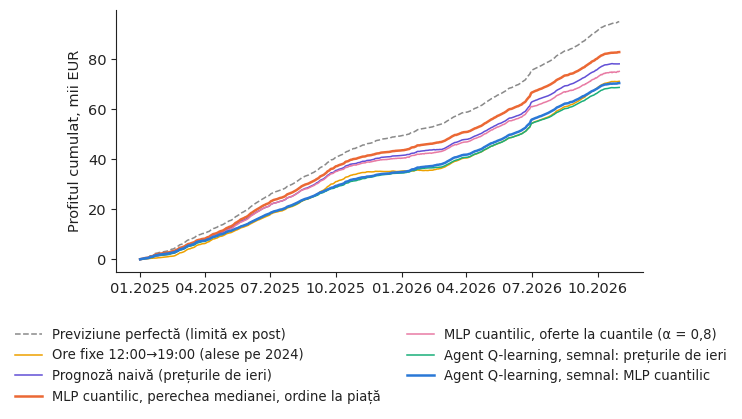

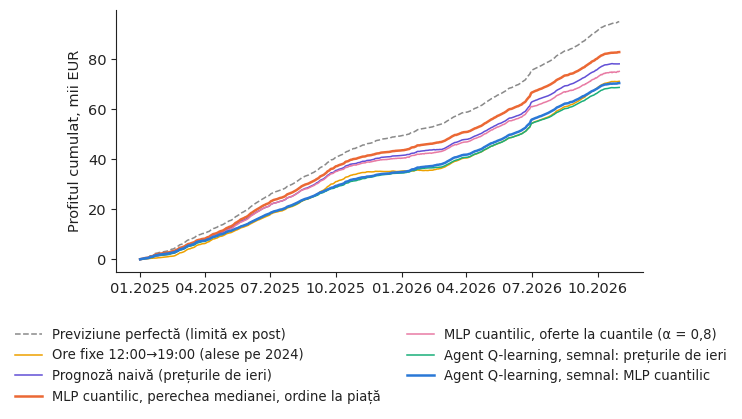

In [10]:
COL = {"pf": cu.MUTED, "nh": cu.PAL["BG"], "naive": cu.PAL["c7"], "mlp_mkt": cu.PAL["DE_LU"], "mlp_qb": cu.PAL["c5"], "rl_naive": cu.PAL["HU"], "rl_mlp": cu.PAL["RO"]}
def series(k):
    if k in res:
        return res[k]
    if k == "mlp_mkt":
        return np.mean([mlp_mkt[s] for s in SEEDS], 0)
    if k == "mlp_qb":
        return np.mean([mlp_qb[s][0] for s in SEEDS], 0)
    return np.mean([AG[(k[3:], s)]["test"] for s in SEEDS], 0)
dd = days[TEST]
def fig_cum(lang):
    fig, ax = plt.subplots(figsize=(6.8, 3.4))
    for k in LBL:
        ax.plot(dd, np.cumsum(series(k)) / 1000, color=COL[k], lw=1.8 if k in ("rl_mlp", "mlp_mkt") else 1.1,
                ls="--" if k == "pf" else "-", label=cu.T(lang, *LBL[k]).replace("$\\alpha$", "α").replace("$\\rightarrow$", "→"))
    ax.set_ylabel(cu.T(lang, "Cumulative profit, thousand EUR", "Profitul cumulat, mii EUR"))
    import matplotlib.dates as mdates
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m.%Y" if lang == "ro" else "%Y-%m"))
    cu.comma_axis(ax, lang)
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_cum, "f3_cumulative_profit", headline=True)

In [11]:
mm = acc.mean(); sd_ = acc.std()
rq = tab.loc["rl_mlp"]; rn = tab.loc["rl_naive"]; mk = tab.loc["mlp_mkt"]; qb = tab.loc["mlp_qb"]
cu.write_numbers({
    "nTest": len(TEST), "nTrainOne": len(TR1), "nTrainTwo": len(TR2), "nAgentDays": len(OUT1),
    "pfW": pfW, "nhW": nhW.sum(), "nhWPair": f"{pairW[0]:02d}:00$\\rightarrow${pairW[1]:02d}:00",
    "mae": mm["MAE"], "maeSd": sd_["MAE"], "crps": mm["CRPS"], "cover": mm["cover80"], "maeNaive": naive_mae,
    "pairNew": f"{pair24[0]:02d}:00$\\rightarrow${pair24[1]:02d}:00",
    "pf": tab.loc["pf", "profit"], "pfYear": tab.loc["pf", "year"], "nh": tab.loc["nh", "profit"], "nhYear": tab.loc["nh", "year"],
    "naive": tab.loc["naive", "profit"], "mkt": mk["profit"], "mktSd": mk["sd"], "mktYear": mk["year"],
    "qb": qb["profit"], "qbSd": qb["sd"], "qbBoth": np.mean([mlp_qb[s][1] for s in SEEDS]),
    "rl": rq["profit"], "rlSd": rq["sd"], "rlYear": rq["year"], "rlNPV": rq["NPV"], "rlPay": rq["payback"], "rlBe": rq["be_capex"],
    "rln": rn["profit"], "rlnSd": rn["sd"],
    "bestYear": real.loc[best_real, "year"], "bestNPV": real.loc[best_real, "NPV"], "bestPay": real.loc[best_real, "payback"], "bestBe": real.loc[best_real, "be_capex"],
    "bestName": LBL[best_real],
    "bestShare": 100 * real.loc[best_real, "profit"] / tab.loc["pf", "profit"], "rlShare": 100 * rq["profit"] / tab.loc["pf", "profit"],
    "need": NEED, "ann": ANN, "pfNPV": tab.loc["pf", "NPV"], "pfPay": tab.loc["pf", "payback"],
}, digits={"pfW": 0, "nhW": 0, "mae": 2, "maeSd": 2, "crps": 2, "cover": 1, "maeNaive": 2, "pf": 0, "pfYear": 0, "nh": 0, "nhYear": 0, "naive": 0,
           "mkt": 0, "mktSd": 0, "mktYear": 0, "qb": 0, "qbSd": 0, "qbBoth": 1, "rl": 0, "rlSd": 0, "rlYear": 0, "rlNPV": 0, "rlPay": 1, "rlBe": 0,
           "rln": 0, "rlnSd": 0, "bestYear": 0, "bestNPV": 0, "bestPay": 1, "bestBe": 0, "bestShare": 1, "rlShare": 1, "need": 0, "ann": 3, "pfNPV": 0, "pfPay": 1})
print(open("numbers_en.tex", encoding="utf-8").read())

% generated by the case notebook -- do not edit
\newcommand{\NnTest}{658}
\newcommand{\NnTrainOne}{1,318}
\newcommand{\NnTrainTwo}{2,037}
\newcommand{\NnAgentDays}{719}
\newcommand{\NpfW}{187,456}
\newcommand{\NnhW}{128,711}
\newcommand{\NnhWPair}{03:00$\rightarrow$19:00}
\newcommand{\Nmae}{23.92}
\newcommand{\NmaeSd}{0.35}
\newcommand{\Ncrps}{19.11}
\newcommand{\Ncover}{75.0}
\newcommand{\NmaeNaive}{27.43}
\newcommand{\NpairNew}{12:00$\rightarrow$19:00}
\newcommand{\Npf}{95,053}
\newcommand{\NpfYear}{52,727}
\newcommand{\Nnh}{71,205}
\newcommand{\NnhYear}{39,498}
\newcommand{\Nnaive}{78,176}
\newcommand{\Nmkt}{82,878}
\newcommand{\NmktSd}{1,038}
\newcommand{\NmktYear}{45,973}
\newcommand{\Nqb}{75,169}
\newcommand{\NqbSd}{1,450}
\newcommand{\NqbBoth}{71.0}
\newcommand{\Nrl}{70,488}
\newcommand{\NrlSd}{1,679}
\newcommand{\NrlYear}{39,100}
\newcommand{\NrlNPV}{$-$143,878}
\newcommand{\NrlPay}{12.8}
\newcommand{\NrlBe}{356,122}
\newcommand{\Nrln}{68,755}
\newcommand{\NrlnSd}{140}
\newcomm

In [12]:
# slide-ready summary for the lecture box "Research from our group" (max 6 lines), both languages; every number comes from this notebook
for lang in ("en", "ro"):
    F = lambda v, nd=1: cu.fmt(float(v), nd, lang)
    t_ = lambda en, ro: ro if lang == "ro" else en
    lines = [
        t_("\\textbf{Battery arbitrage with probabilistic forecasts} (Andrei, Cepoi, Dumitrescu, Lessmann, Chiriac (Luchian), Pele \\& Petukhina, 2026, SSRN): forecast-based bids beat fixed hours in all four markets, yet no strategy repays a 500,000 EUR battery (Section~6.2).",
           "\\textbf{Arbitrajul cu baterii pe baza prognozelor probabilistice} (Andrei, Cepoi, Dumitrescu, Lessmann, Chiriac (Luchian), Pele și Petukhina, 2026, SSRN): ofertele bazate pe prognoză depășesc orele fixe pe toate cele patru piețe, dar nicio strategie nu recuperează o baterie de 500.000 EUR (secțiunea~6.2)."),
        t_(f"Our replication (Romania, test 2025--October 2026, five seeds): quantile MLP with the median pair {F(mk['year'] / 1e3)} thousand EUR/year, Q-learning agent {F(rq['year'] / 1e3)}, fixed hours {F(tab.loc['nh', 'year'] / 1e3)}, perfect foresight {F(tab.loc['pf', 'year'] / 1e3)}.",
           f"Replicarea noastră (România, test 2025--octombrie 2026, cinci seeds): MLP cuantilic cu perechea medianei {F(mk['year'] / 1e3)} mii EUR/an, agent Q-learning {F(rq['year'] / 1e3)}, ore fixe {F(tab.loc['nh', 'year'] / 1e3)}, previziune perfectă {F(tab.loc['pf', 'year'] / 1e3)}."),
        t_(f"Profit needed to repay 500,000 EUR in 15 years at 7\\,\\%: {F(NEED / 1e3)} thousand EUR/year --- value storage on realistic strategies, not on perfect foresight.",
           f"Profitul necesar pentru a recupera 500.000 EUR în 15 ani, la 7\\,\\%: {F(NEED / 1e3)} mii EUR/an --- evaluați stocarea după strategiile realiste, nu după previziunea perfectă."),
    ]
    with open(f"slide_summary_{lang}.tex", "w", encoding="utf-8") as fh:
        fh.write("% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook\n\\begin{itemize}\\setlength{\\itemsep}{2pt}\n")
        for l_ in lines:
            fh.write("  \\item " + l_ + "\n")
        fh.write("\\end{itemize}\n")
print(open("slide_summary_en.tex", encoding="utf-8").read())

% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook
\begin{itemize}\setlength{\itemsep}{2pt}
  \item \textbf{Battery arbitrage with probabilistic forecasts} (Andrei, Cepoi, Dumitrescu, Lessmann, Chiriac (Luchian), Pele \& Petukhina, 2026, SSRN): forecast-based bids beat fixed hours in all four markets, yet no strategy repays a 500,000 EUR battery (Section~6.2).
  \item Our replication (Romania, test 2025--October 2026, five seeds): quantile MLP with the median pair 46.0 thousand EUR/year, Q-learning agent 39.1, fixed hours 39.5, perfect foresight 52.7.
  \item Profit needed to repay 500,000 EUR in 15 years at 7\,\%: 54.9 thousand EUR/year --- value storage on realistic strategies, not on perfect foresight.
\end{itemize}



## Exerciții suplimentare
1. Dați agentului o stare mai bogată: adăugați lățimea intervalului de prognoză 10 %-90 % pentru ora h (în două clase). Învață agentul să evite orele incerte?
2. Permiteți două cicluri pe zi (noapte-prînz și prînz-seară). Cu cît crește profitul bateriei în 2025-2026, cînd energia de la prînz este ieftină?
3. Înlocuiți agentul tabelar cu o rețea Q profundă (DQN, *deep Q-network*, cursul 10) care vede întreaga prognoză pe 24 de ore. Merită cîștigul complexitatea suplimentară, pe cinci seeds?